<a href="https://colab.research.google.com/github/Faisaleka21/Deep_Learning/blob/main/Pertemuan_6_Performance_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import torch
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn   #praktikum 5

In [33]:
# # 1. muat model
# model = torch.load('model_harga_rumah.pth')
# model.eval()

In [34]:
# kode training di praktikum 5
# ==========================================================
# definisi model (3 in -> 1 out)
model = nn.Sequential(
    nn.Linear(3, 16),     # input : 3, hidden: 16
    nn.ReLU(),
    nn.Linear(16, 1),     # hidden: 16, output: 1
)

In [35]:
# kode training di praktikum 5
# ==========================================================
# Berdasarkan data tabel (Luas Tanah, Luas Bangunan, Jumlah Kamar)
x = torch.tensor([[90.0, 60.0, 2.0],   #[1]
                  [120.0, 80.0, 3.0],  #[2]
                  [150.0, 110.0, 3.0], #[3]
                  [200.0, 150.0, 4.0], #[4]
                  [250.0, 180.0, 4.0]  #[5]
                  ])

# Target data (Harga Juta Rp)
y = torch.tensor([[420.0],  #[1]
                  [610.0],  #[2]
                  [780.0],  #[3]
                  [1120.0], #[4]
                  [1350.0]  #[5]
                  ])

In [36]:
# kode training di praktikum 5
# ==========================================================
# 2 Loss function dan optimizer
criterion = nn.MSELoss()    #fungsi loss (MSE)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)    # Algortima optimizer Adam

In [37]:
# kode training di praktikum 5
# ==========================================================
# 3 Training Loop
x = X_train = x
y = y_train = y

# Inisialisasi list untuk menyimpan loss history
loss_history = []

for epoch in range(200):
  optimizer.zero_grad()               # Reset gradient
  y_pred = model(X_train)             # Forward
  loss = criterion(y_pred, y_train)   # Hitung Loss
  loss.backward()                     # backward: hitung gradient
  optimizer.step()                    # update parameter

  # Simpan loss untuk grafik
  loss_history.append(loss.item())

  if (epoch+1) % 20 == 0:
    print(f'Epoch [{epoch+1:3d} | Loss: {loss.item():.4f}')

Epoch [ 20 | Loss: 822471.6250
Epoch [ 40 | Loss: 791157.1250
Epoch [ 60 | Loss: 759466.8750
Epoch [ 80 | Loss: 725704.1875
Epoch [100 | Loss: 688721.8750
Epoch [120 | Loss: 647828.8125
Epoch [140 | Loss: 603279.0625
Epoch [160 | Loss: 555479.3125
Epoch [180 | Loss: 504447.3125
Epoch [200 | Loss: 451178.9375


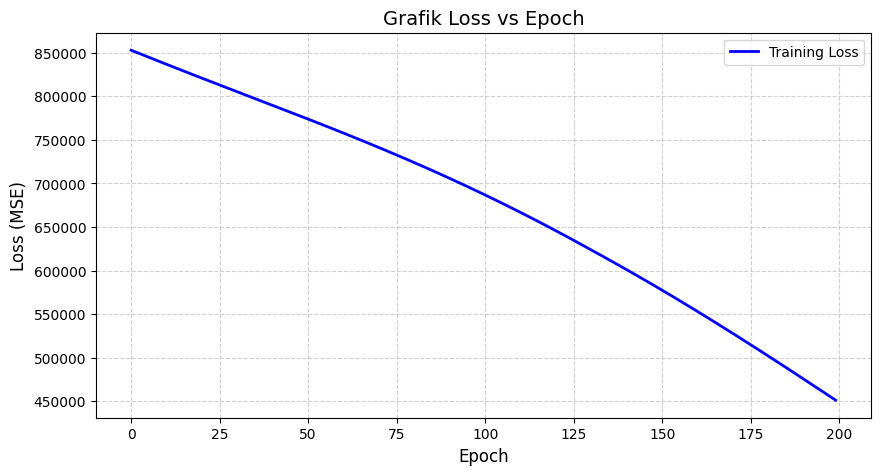

In [38]:
# kode training di praktikum 5
# ==========================================================
# 4 Visualisasi Loss vs Epoch
plt.figure(figsize=(10, 5))
plt.plot(loss_history, label='Training Loss', color='blue', linewidth=2)
plt.title('Grafik Loss vs Epoch', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss (MSE)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [39]:
# 1. Definisi Data Uji (Test Data)
# Kita buat data uji baru untuk mengevaluasi model
X_test = torch.tensor([
    [100.0, 70.0, 2.0],  # Rumah 1
    [180.0, 130.0, 4.0]  # Rumah 2
])

y_test = np.array([
    [500.0],  # Target harga aktual Rumah 1
    [1000.0]  # Target harga aktual Rumah 2
])

In [40]:
# 2. prediksi data uji
with torch.no_grad():
  y_pred = model(X_test).numpy().flatten()

In [41]:
# 3. hitung matrix evaluasi
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# 4. Tampilkan hasil evaluasi
print(f'MAE: {mae:.2f}')
print(f'MSE: {mse:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R2: {r2:.2f}')

MAE: 546.12
MSE: 334657.39
RMSE: 578.50
R2: -4.35


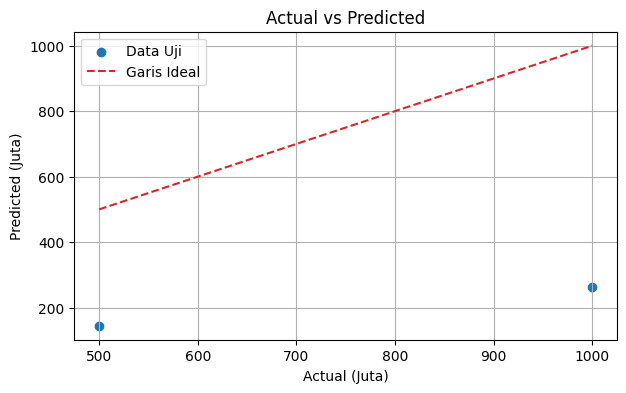

In [42]:
# 5. Visualisasi Actual vs Predicted
plt.figure(figsize=(7, 4))
plt.scatter(y_test, y_pred,color='tab:blue', label='Data Uji')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='tab:red', linestyle='--', label='Garis Ideal')
plt.xlabel('Actual (Juta)')
plt.ylabel('Predicted (Juta)')
plt.title('Actual vs Predicted')
plt.legend()
plt.grid(True)
plt.show()